In [12]:
!pip install tensorflow

In [13]:
import tensorflow as tf
from tensorflow import keras

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [14]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Input Shape :", X.shape)
print("Output Shape:", y.shape)

Input Shape : (569, 30)
Output Shape: (569,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [16]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [17]:
model = keras.Sequential([
    keras.layers.Dense(
        1,
        activation='sigmoid',
        input_shape=(30,)
    )
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [19]:
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    validation_data=(X_test, y_test)
)

Epoch 1/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8791 - loss: 0.3478 - val_accuracy: 0.9298 - val_loss: 0.3074
Epoch 2/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8923 - loss: 0.3198 - val_accuracy: 0.9386 - val_loss: 0.2809
Epoch 3/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9055 - loss: 0.2961 - val_accuracy: 0.9386 - val_loss: 0.2591
Epoch 4/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9077 - loss: 0.2769 - val_accuracy: 0.9386 - val_loss: 0.2406
Epoch 5/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9165 - loss: 0.2604 - val_accuracy: 0.9386 - val_loss: 0.2251
Epoch 6/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9187 - loss: 0.2463 - val_accuracy: 0.9386 - val_loss: 0.2113
Epoch 7/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9275 - loss: 0.2339 - val_accuracy: 0.9386 - val_loss: 0.1999
Epoch 8/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9319 - loss: 0.2231 - val_accuracy: 0.9474 - val_l

In [20]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss :", loss)
print("Test Accuracy :", accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9737 - loss: 0.1082
Test Loss : 0.10818827897310257
Test Accuracy : 0.9736841917037964


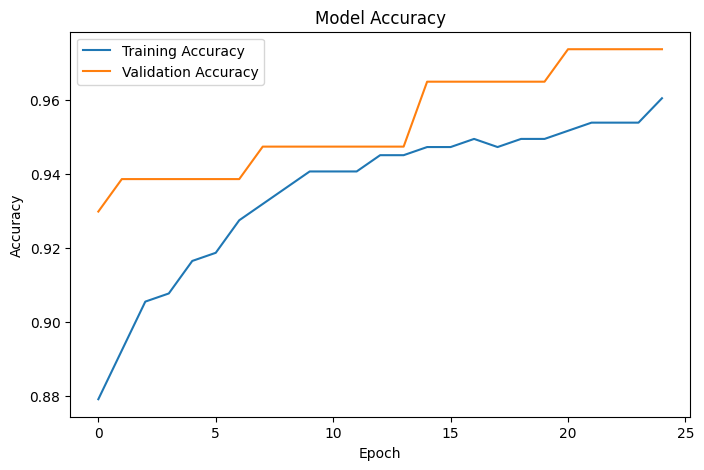

In [21]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

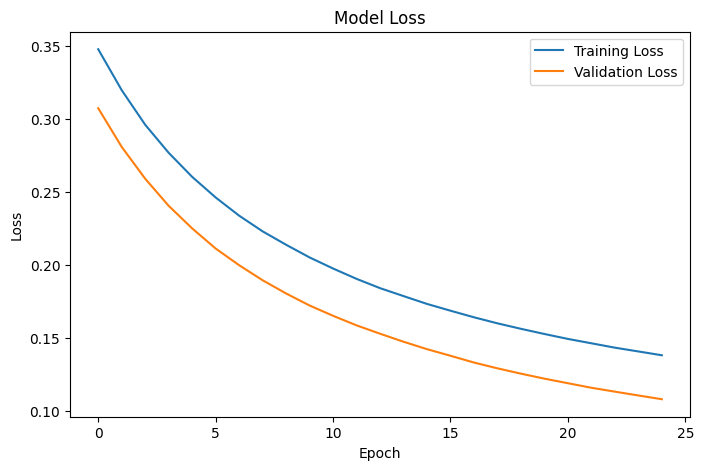

In [22]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()